# 1. Modulazione e canale

---

## 7.1 Il problema della comunicazione

### Definizione 7.1.1 — Il modello di Shannon

Il **modello di Shannon** della comunicazione descrive il problema in termini astratti:

$$
\text{Sorgente} \;\to\; \text{Codificatore di sorgente} \;\to\; \text{Codificatore di canale} \;\to\; \text{Modulatore} \;\to\; \text{Canale} \;\to\; \text{Demodulatore} \;\to\; \text{Decodificatore} \;\to\; \text{Destinazione}
$$

In una ground station, la **sorgente** è il veicolo spaziale (che genera telemetria), il **canale** è il link radio, e la **destinazione** è il ricevitore a terra (che produce frame). I blocchi intermedi svolgono funzioni precise:

- **Codificatore di sorgente**: comprime i dati rimuovendo la ridondanza *strutturale* (es. compressione, predizione differenziale). Non introduce ridondanza, la rimuove.
- **Codificatore di canale**: aggiunge ridondanza *controllata* (FEC) per proteggere i dati dagli errori del canale. Trattato nel capitolo 10.
- **Modulatore**: trasforma i bit in una forma d'onda adatta al canale.
- **Demodulatore**: stima i bit a partire dalla forma d'onda ricevuta.

Questo capitolo si concentra sugli ultimi due blocchi e sul canale che li separa.

### Osservazione 7.1.2 — Due problemi distinti: rappresentazione e decisione

La comunicazione digitale affronta due problemi distinti, spesso confusi:

1. **Rappresentazione**: come associare a ogni sequenza di bit una forma d'onda che possa viaggiare nel canale. Questo è il problema della **modulazione**.
2. **Decisione**: come, a partire dalla forma d'onda ricevuta (corrotta dal rumore), stimare la sequenza di bit trasmessa. Questo è il problema della **rivelazione** (detection).

I due problemi sono collegati ma distinti: la scelta della modulazione determina **quanto sono separabili** i segnali nel ricevitore, e quindi la **probabilità di errore**; la scelta della regola di decisione determina **quanto bene** il ricevitore sfrutta quella separabilità. La teoria ottima (rivelazione ML) è nota; la sfida è implementarla in modo efficiente e con complessità accettabile.

---

## 7.2 Il canale come processo stocastico

### Definizione 7.2.1 — Canale AWGN

Il modello di canale più semplice e fondamentale è il **canale AWGN** (Additive White Gaussian Noise): il segnale ricevuto è

$$
r(t) = s(t) + n(t)
$$

dove $s(t)$ è il segnale trasmesso e $n(t)$ è un **rumore bianco gaussiano**: un processo stocastico con media zero, varianza $\sigma_n^2$, e densità spettrale di potenza **costante** su tutte le frequenze:

$$
S_n(f) = \frac{N_0}{2} \quad \forall f
$$

(dove $N_0/2$ è la densità spettrale bilatera; la densità monolatera è $N_0$). Il fattore $1/2$ è una convenzione: la potenza totale del rumore in una banda $B$ è $N_0 B$ (monolatera).

> **Osservazione 7.2.2 — "Bianco" e "gaussiano" sono due proprietà distinte.**  
> "Bianco" significa che la densità spettrale è costante: il rumore ha la stessa potenza a tutte le frequenze, e le sue realizzazioni a istanti diversi sono **non correlate** (in realtà, nel caso gaussiano, indipendenti). "Gaussiano" significa che le ampiezze sono distribuite secondo una normale. Le due proprietà sono indipendenti: esiste rumore bianco non gaussiano (es. rumore impulsivo), e rumore gaussiano non bianco (es. rumore colorato, con densità spettrale non costante). Il rumore termico è **sia** bianco **sia** gaussiano (per il teorema del limite centrale, essendo la somma di molti contributi indipendenti), ed è il modello di riferimento per i canali radio.

### Definizione 7.2.3 — Rapporto segnale-rumore per bit (Eb/N0)

La metrica fondamentale per confrontare le prestazioni delle modulazioni è il **rapporto segnale-rumore per bit**, definito come:

$$
\frac{E_b}{N_0} = \frac{P_s T_b}{N_0} = \frac{P_s}{N_0 R_b}
$$

dove $E_b = P_s T_b$ è l'energia per bit, $P_s$ è la potenza del segnale, $T_b$ è la durata di un bit, e $R_b = 1/T_b$ è il bit rate. $N_0$ è la densità spettrale monolatera del rumore.

**Perché $E_b/N_0$ e non $P_s/N$?** Perché $E_b/N_0$ misura l'energia **per bit** rispetto al rumore, indipendentemente dalla banda e dal bit rate. Due sistemi con lo stesso $E_b/N_0$ hanno la stessa probabilità di errore per bit, anche se operano a frequenze, bande e potenze diverse. È la metrica **normalizzata** che permette il confronto tra modulazioni diverse.

La relazione con l'SNR (rapporto segnale-rumore in banda) è:

$$
\frac{E_b}{N_0} = \frac{S}{N} \cdot \frac{B}{R_b} = \text{SNR} \cdot \eta_B
$$

dove $B$ è la banda del segnale e $\eta_B = B/R_b$ è l'**efficienza spettrale** (bit/s per Hz). Questa relazione è cruciale: mostra che, a parità di $E_b/N_0$, un sistema con efficienza spettrale più alta richiede un SNR più alto (perché più bit sono "compressi" nella stessa banda).

### Osservazione 7.2.4 — Il rumore come variabile aleatoria

In un canale AWGN, il segnale ricevuto in un istante $t$ è una variabile aleatoria:

$$
R(t) = s(t) + N(t), \quad N(t) \sim \mathcal{N}(0, \sigma_n^2)
$$

La densità di probabilità di $R(t)$ condizionata a $s(t)$ è:

$$
p_{R|S}(r|s) = \frac{1}{\sqrt{2\pi\sigma_n^2}} \exp\left(-\frac{(r - s)^2}{2\sigma_n^2}\right)
$$

Questa è la **verosimiglianza** del segnale ricevuto $r$ dato il segnale trasmesso $s$. È il punto di partenza della rivelazione ottima: il ricevitore sceglie il segnale $s$ che **massimizza** questa verosimiglianza, cioè il segnale più "plausibile" dato ciò che ha ricevuto.

### Definizione 7.2.5 — Canali più realistici

Il canale AWGN è un'idealizzazione. I canali reali presentano fenomeni aggiuntivi che vanno modellati statisticamente:

**Fading (dissolvenza).** L'ampiezza del segnale ricevuto varia nel tempo a causa di:
- **Multipath**: il segnale arriva al ricevitore attraverso più percorsi (riflessioni, diffrazioni), con ritardi e fasi diverse. La somma vettoriale dei contributi produce variazioni di ampiezza e fase.
- **Ostruzione**: ostacoli fisici tra trasmettitore e ricevitore attenuano il segnale.
- **Moto relativo**: il movimento del veicolo o del ricevitore produce variazioni Doppler.

Il fading si modella come una **variabile aleatoria** che moltiplica l'ampiezza del segnale:

$$
r(t) = \alpha(t) s(t) + n(t)
$$

dove $\alpha(t)$ è il **guadagno di canale**. I modelli tipici sono:
- **Rayleigh fading**: $|\alpha|$ è distribuito secondo una Rayleigh. Modella canali senza linea di vista diretta (NLOS), tipici delle comunicazioni urbane o con ostacoli.
- **Rician fading**: $|\alpha|$ è distribuito secondo una Rice, con un parametro $K$ che rappresenta il rapporto tra la potenza della componente diretta e quella diffusa. Per $K \to 0$ degenera in Rayleigh; per $K \to \infty$ degenera in AWGN (canale ideale con linea di vista).
- **Nakagami-m**: distribuzione più generale, con parametro $m$ che controlla la severità del fading.

**Doppler shift.** Il movimento relativo tra trasmettitore e ricevitore produce uno spostamento in frequenza:

$$
f_D = \frac{v}{c} f_c \cos\theta
$$

dove $v$ è la velocità relativa, $c$ è la velocità della luce, $f_c$ è la frequenza portante, $\theta$ è l'angolo tra la direzione del moto e la direzione di arrivo. Per un satellite LEO a 7 km/s e una portante a 437 MHz, il Doppler massimo è circa $\pm 10$ kHz. Il ricevitore deve **stimare e compensare** questo spostamento, altrimenti il segnale esce dalla banda del filtro.

> **Osservazione 7.2.6 — Il fading è il fenomeno che distingue i canali reali da AWGN.**  
> In un canale AWGN, la probabilità di errore dipende solo da $E_b/N_0$, che è costante. In un canale con fading, $E_b/N_0$ **varia nel tempo** in modo aleatorio, e la probabilità di errore è una **media** su questa distribuzione. Il risultato è che, a parità di $E_b/N_0$ medio, un canale con fading ha prestazioni molto peggiori di un canale AWGN. Questo è il motivo per cui, nelle comunicazioni spaziali, si usano tecniche di **diversity** (più antenne, più frequenze, più istanti) per mitigare il fading: combinando più osservazioni indipendenti, la probabilità che tutte siano in fade profondo diminuisce esponenzialmente.

---

## 7.3 Rappresentazione geometrica dei segnali

### Definizione 7.3.1 — Spazio dei segnali

Un insieme di $M$ segnali $s_1(t), \dots, s_M(t)$, ciascuno di durata $T$ e energia finita, può essere rappresentato come un insieme di **vettori** in uno spazio euclideo di dimensione $N \le M$. La costruzione si basa sulla **procedura di Gram-Schmidt**:

1. Si prende il primo segnale $s_1(t)$ e si normalizza: $\phi_1(t) = s_1(t)/\|s_1\|$, dove $\|s\| = \sqrt{\int_0^T s^2(t) dt}$.
2. Per ogni segnale successivo $s_i(t)$, si sottrae la proiezione sugli $\phi_j$ già costruiti, e si normalizza il residuo. Se il residuo è zero, il segnale è linearmente dipendente dai precedenti e non contribuisce a una nuova dimensione.

Il risultato è una **base ortonormale** $\{\phi_1, \dots, \phi_N\}$ tale che ogni segnale $s_i(t)$ si scrive come:

$$
s_i(t) = \sum_{k=1}^N s_{ik} \phi_k(t), \quad s_{ik} = \int_0^T s_i(t) \phi_k(t) dt
$$

Il vettore $\mathbf{s}_i = (s_{i1}, \dots, s_{iN})$ è la **rappresentazione** del segnale $s_i(t)$ nello spazio dei segnali.

### Osservazione 7.3.2 — Perché la rappresentazione geometrica è utile

La rappresentazione geometrica trasforma un problema di **segnali** (funzioni del tempo) in un problema di **punti** in uno spazio euclideo. Questo permette di:

1. **Visualizzare** la modulazione: una modulazione è un insieme di punti (la **costellazione**) in uno spazio a 1, 2, o più dimensioni.
2. **Calcolare** la probabilità di errore: dipende dalla **distanza euclidea** tra i punti della costellazione, non dalla forma d'onda.
3. **Progettare** il ricevitore: la rivelazione ottima si riduce a trovare il punto della costellazione più vicino al vettore ricevuto.
4. **Confrontare** modulazioni diverse: due costellazioni con la stessa distanza minima hanno la stessa probabilità di errore, indipendentemente dalla forma d'onda.

> **Osservazione 7.3.3 — La distanza minima decide tutto.**  
> La probabilità di errore di una modulazione, in un canale AWGN, è dominata dalla **distanza minima** $d_{\min}$ tra i punti della costellazione:
> 
> $$
> d_{\min} = \min_{i \ne j} \|\mathbf{s}_i - \mathbf{s}_j\|
> $$
> 
> Più grande è $d_{\min}$, più i punti sono separati, e più è improbabile che il rumore sposti il vettore ricevuto da un punto all'altro. L'energia media per simbolo $E_s$ è legata alla geometria della costellazione; il rapporto $d_{\min}^2/E_s$ è una misura dell'**efficienza energetica** della modulazione. Massimizzare questo rapporto, a parità di numero di punti $M$, è l'obiettivo del progetto della costellazione.

### Definizione 7.3.4 — Costellazioni tipiche

Le modulazioni si classificano in base alla geometria della costellazione:

**PAM (Pulse Amplitude Modulation).** Costellazione **unidimensionale**: i punti sono disposti su una retta. Con $M = 2^k$ livelli, si trasmettono $k$ bit per simbolo. Esempio: 2-PAM (BPSK), 4-PAM, 8-PAM.

**PSK (Phase Shift Keying).** Costellazione **bidimensionale** disposta su un cerchio: i punti hanno tutti la stessa ampiezza e fasi diverse. Esempio: BPSK (2 punti, fasi $0, \pi$), QPSK (4 punti, fasi $\pi/4, 3\pi/4, 5\pi/4, 7\pi/4$), 8-PSK (8 punti).

**QAM (Quadrature Amplitude Modulation).** Costellazione **bidimensionale** a griglia rettangolare: i punti hanno ampiezze e fasi variabili. Esempio: 16-QAM (griglia $4 \times 4$), 64-QAM (griglia $8 \times 8$), 256-QAM (griglia $16 \times 16$).

**FSK (Frequency Shift Keying).** Costellazione **ortogonale**: i punti sono disposti su assi ortogonali in uno spazio a $M$ dimensioni. Ogni simbolo occupa una dimensione diversa. Esempio: 2-FSK (2 frequenze), 4-FSK, $M$-FSK.

> **Osservazione 7.3.5 — Ortogonalità e PSK/QAM sono filosofie diverse.**  
> PSK e QAM **impacchettano** più punti in poche dimensioni (2), aumentando l'efficienza spettrale ma riducendo la distanza minima. FSK **distribuisce** i punti su molte dimensioni, mantenendo la distanza minima ma riducendo l'efficienza spettrale. È un trade-off fondamentale: PSK/QAM sono **bandwidth-efficient**, FSK è **power-efficient**. La scelta dipende dal vincolo dominante: se la banda è scarsa (es. link satellitare commerciale), si usa PSK/QAM; se la potenza è scarsa (es. sonde deep-space), si usa FSK ortogonale.

---

## 7.4 Famiglie di modulazione

### Definizione 7.4.1 — Modulazioni lineari

Una modulazione si dice **lineare** se il segnale modulato è una combinazione lineare dei simboli (i punti della costellazione):

$$
s(t) = \sum_{n} a_n \, g(t - nT)
$$

dove $a_n$ è il simbolo (complesso) e $g(t)$ è la **forma d'impulso** (pulse shape). La linearità si riferisce al fatto che il segnale è una somma di impulsi pesati dai simboli.

**PSK e QAM sono modulazioni lineari.** Il segnale passa-banda è:

$$
s(t) = \text{Re}\left\{ \sum_n a_n \, g(t - nT) \, e^{j2\pi f_c t} \right\}
$$

dove $a_n = I_n + jQ_n$ è il simbolo complesso, con $I_n$ e $Q_n$ le componenti in fase e in quadratura. La costellazione è l'insieme dei possibili valori di $a_n$.

**BPSK**: $a_n \in \{-1, +1\}$. Un bit per simbolo. Distanza minima $d_{\min} = 2\sqrt{E_b}$ (in unità di ampiezza), energia per bit $E_b$.

**QPSK**: $a_n \in \{(1+j)/\sqrt{2}, (-1+j)/\sqrt{2}, (-1-j)/\sqrt{2}, (1-j)/\sqrt{2}\}$. Due bit per simbolo. La distanza minima è la stessa di BPSK a parità di energia per bit, ma il simbolo trasporta 2 bit, quindi a parità di $E_b/N_0$ la probabilità di errore per bit è simile.

**16-QAM**: $a_n = I_n + jQ_n$ con $I_n, Q_n \in \{-3, -1, +1, +3\}$ (scalati opportunamente). Quattro bit per simbolo. La distanza minima è più piccola di BPSK a parità di energia media per simbolo, quindi serve più $E_b/N_0$ per la stessa probabilità di errore.

> **Osservazione 7.4.2 — L'efficienza spettrale e la potenza sono in conflitto.**  
> Aumentare il numero di punti $M$ della costellazione aumenta l'efficienza spettrale ($\log_2 M$ bit per simbolo) ma riduce la distanza minima (a parità di energia media), peggiorando la probabilità di errore. Il compromesso è quantificato dalla **penalità di potenza**: per passare da BPSK a QPSK (raddoppio dell'efficienza spettrale) non c'è penalità in $E_b/N_0$ (a parità di probabilità di errore per bit); per passare da QPSK a 16-QAM serve circa 4 dB in più di $E_b/N_0$; per passare da 16-QAM a 64-QAM servono altri 6 dB. È la regola dei "3 dB per bit" (approssimativamente) per le modulazioni QAM.

### Definizione 7.4.3 — Modulazioni ortogonali: FSK

Nella **FSK** (Frequency Shift Keying), ogni simbolo corrisponde a una **frequenza diversa**. Con $M$ simboli, si usano $M$ frequenze $f_1, \dots, f_M$, ortogonali tra loro sull'intervallo di simbolo $T$:

$$
\int_0^T \cos(2\pi f_i t) \cos(2\pi f_j t) dt = 0 \quad \text{per } i \ne j
$$

(condizione di ortogonalità: $|f_i - f_j| = k/(2T)$ per qualche intero $k$).

Il segnale trasmesso per il simbolo $m$ è:

$$
s_m(t) = \sqrt{\frac{2E_s}{T}} \cos(2\pi f_m t), \quad 0 \le t \le T
$$

dove $E_s$ è l'energia per simbolo. La costellazione è ortogonale: i punti sono disposti su assi ortogonali in uno spazio a $M$ dimensioni.

**FSK coerente**: il ricevitore conosce la fase del segnale (sincronizzazione di fase). **FSK non coerente**: il ricevitore non conosce la fase, e usa una rivelazione di energia (inviluppo). La FSK non coerente è più robusta (non richiede sincronizzazione di fase) ma ha prestazioni peggiori di circa 3 dB rispetto alla FSK coerente.

> **Osservazione 7.4.4 — La FSK è power-efficient ma bandwidth-hungry.**  
> A parità di $E_b/N_0$, la FSK ortogonale con $M$ grande ha una probabilità di errore che **diminuisce** con $M$ (perché la distanza minima tra i punti cresce con $M$). Tuttavia, l'efficienza spettrale è $\log_2 M / M$ bit/s per Hz, che **diminuisce** con $M$. Per $M$ grande, la FSK richiede una banda enorme per un throughput modesto. È la modulazione tipica per i link deep-space, dove la potenza è il vincolo dominante e la banda è abbondante.

### Definizione 7.4.5 — Modulazioni a fase continua: CPM, MSK, GMSK

Le modulazioni **CPM** (Continuous Phase Modulation) hanno la proprietà che la fase del segnale è **continua** nel tempo, anche ai confini tra simboli. Questo riduce l'occupazione spettrale (meno brusche transizioni → meno componenti ad alta frequenza) ma complica la rivelazione.

**MSK** (Minimum Shift Keying) è una CPM con indice di modulazione $h = 1/2$: la differenza di fase tra simboli consecutivi è $\pm \pi/2$. Ha una densità spettrale più compatta di QPSK, ma la stessa probabilità di errore (a parità di $E_b/N_0$).

**GMSK** (Gaussian MSK) è una MSK con un filtro gaussiano passa-basso prima della modulazione. Il filtro riduce ulteriormente l'occupazione spettrale, al costo di un piccolo peggioramento della probabilità di errore (interferenza intersimbolica). È la modulazione usata in **GSM** e in molti link radio per CubeSat (es. LoRa usa una variante di chirp spread spectrum).

> **Osservazione 7.4.6 — La scelta della forma d'impulso è una scelta spettrale.**  
> La forma d'impulso $g(t)$ determina la **densità spettrale di potenza** del segnale modulato. Impulsi rettangolari hanno spettro con lobi laterali che decadono lentamente (come $\text{sinc}$), occupando molta banda. Impulsi con transizioni morbide (raised cosine, root raised cosine, gaussiano) hanno spettri più compatti. Il **roll-off factor** $\alpha$ del filtro raised cosine controlla il compromesso tra occupazione spettrale (banda $= (1+\alpha)/(2T)$) e robustezza all'ISI. Per $\alpha = 0$ si ha la massima efficienza spettrale ma ISI nulla solo in condizioni ideali; per $\alpha = 1$ si ha il doppio della banda ma robustezza massima.

### Definizione 7.4.7 — Spread spectrum

Le modulazioni **spread spectrum** distribuiscono il segnale su una banda molto più larga di quella strettamente necessaria, usando un **codice** noto al ricevitore. Il vantaggio è la **robustezza** a interferenze, il **basso SNR** richiesto (grazie al processing gain), e la **riservatezza** (senza il codice, il segnale è indistinguibile dal rumore).

**DSSS** (Direct Sequence Spread Spectrum): ogni bit è moltiplicato per una sequenza pseudo-casuale (chipping sequence) di $N$ chip. La banda occupata è $N$ volte quella del segnale originale; il **processing gain** è $10\log_{10} N$ dB. Il ricevitore correlа il segnale ricevuto con la stessa sequenza, recuperando il segnale originale e rigettando il rumore e le interferenze.

**FHSS** (Frequency Hopping Spread Spectrum): la frequenza portante cambia periodicamente secondo una sequenza pseudo-casuale. Il ricevitore segue la stessa sequenza. È robusto a interferenze a banda stretta e a fading selettivo.

**LoRa** (Long Range): una modulazione **chirp spread spectrum** proprietaria di Semtech. Ogni simbolo è una chirp (spazzata in frequenza) con pendenza che codifica il simbolo. Grazie al processing gain, LoRa può decodificare segnali con SNR **negativo** (fino a -20 dB). È la modulazione usata in molti CubeSat e in J2050, per la sua capacità di comunicare a basso consumo e lunga distanza.

> **Osservazione 7.4.8 — LoRa e il compromesso tra velocità e sensibilità.**  
> LoRa permette di scegliere lo **spreading factor** (SF) da 7 a 12. Aumentando SF, il bit rate diminuisce (più chip per bit), ma la sensibilità migliora (più processing gain). Ogni incremento di SF raddoppia il tempo di simbolo e migliora l'SNR di circa 3 dB. È un esempio concreto di come la modulazione offra un **parametro di progetto** per adattarsi al link: in condizioni favorevoli si usa SF basso (più velocità), in condizioni difficili SF alto (più robustezza).

---

## 7.5 Rivelazione ottima

### Definizione 7.5.1 — Il problema della decisione

Il ricevitore osserva il segnale $r(t) = s_i(t) + n(t)$, dove $s_i(t)$ è uno degli $M$ possibili segnali trasmessi, e deve decidere **quale** $s_i(t)$ è stato trasmesso. È un problema di **decisione statistica**: dato $r(t)$, scegliere l'ipotesi $H_i$ ("è stato trasmesso $s_i$") che massimizza la probabilità di essere corretta.

La regola ottima è la **massima verosimiglianza (ML)** quando le ipotesi sono equiprobabili, o la **massima probabilità a posteriori (MAP)** quando hanno probabilità diverse:

$$
\hat{i}_{ML} = \arg\max_i \, p(r | s_i), \qquad
\hat{i}_{MAP} = \arg\max_i \, P(s_i) \, p(r | s_i)
$$

Nel canale AWGN, $p(r | s_i)$ è la densità gaussiana centrata su $s_i$. Massimizzarla equivale a minimizzare la distanza euclidea tra $r$ e $s_i$:

$$
\hat{i}_{ML} = \arg\min_i \, \|r - s_i\|^2
$$

Questa è la regola del **minimo errore quadratico** (minimum distance): si sceglie il punto della costellazione più vicino al vettore ricevuto.

### Definizione 7.5.2 — Il filtro adattato (matched filter)

La realizzazione ottima della decisione ML si ottiene con un **filtro adattato** al segnale atteso. Per un segnale $s_i(t)$ di durata $T$, il filtro adattato ha risposta impulsiva:

$$
h_i(t) = s_i(T - t)
$$

e l'uscita campionata a $t = T$ è la **correlazione** tra il segnale ricevuto e $s_i(t)$:

$$
y_i = \int_0^T r(t) s_i(t) dt
$$

Il ricevitore ML calcola $y_i$ per ogni possibile simbolo $i$, e sceglie quello con $y_i$ massimo. Il filtro adattato **massimizza l'SNR** all'istante di campionamento, ed è quindi la scelta ottima per la rivelazione in AWGN.

> **Osservazione 7.5.3 — Il filtro adattato è l'equivalente continuo del prodotto scalare.**  
> In termini geometrici, $y_i$ è la **proiezione** del vettore ricevuto $r$ sulla direzione del segnale $s_i$. Il ricevitore ML sceglie la direzione su cui la proiezione è massima, cioè il segnale più "allineato" con $r$. Questa interpretazione geometrica è utile: la rivelazione è un problema di **proiezione e confronto**, non di "decodifica" nel senso di svelare un codice. La struttura del codice (mappatura bit → simboli) è un livello superiore, non riguarda il demodulatore.

### Osservazione 7.5.4 — Complessità e realizzabilità

Il ricevitore ML richiede di calcolare $M$ correlazioni per ogni simbolo. Per $M$ piccolo (BPSK, QPSK) è banale; per $M$ grande (256-QAM, 1024-QAM) diventa oneroso. In pratica, si usano strutture semplificate:
- **Rivelazione per soglia**: per PAM e QAM, la decisione si riduce a confrontare la componente $I$ e $Q$ con soglie (decisioni indipendenti per ogni dimensione).
- **Rivelazione differenziale**: per PSK, si confronta la fase del simbolo corrente con quella del precedente, senza bisogno di sincronizzazione di fase assoluta (costa circa 3 dB).
- **Rivelazione non coerente**: per FSK, si usa la rivelazione di energia (inviluppo) senza conoscere la fase, al costo di qualche dB.

Questi compromessi tra ottimalità e complessità sono il pane quotidiano del progetto di un demodulatore.

---

## 7.6 Probabilità di errore

### Definizione 7.6.1 — La funzione Q

La probabilità di errore nelle modulazioni digitali si esprime quasi sempre in termini della **funzione Q**, definita come la coda della normale standard:

$$
Q(x) = \frac{1}{\sqrt{2\pi}} \int_x^{+\infty} e^{-t^2/2} dt
$$

Proprietà utili:
- $Q(0) = 1/2$;
- $Q(-x) = 1 - Q(x)$;
- $Q(x) \sim \frac{1}{x\sqrt{2\pi}} e^{-x^2/2}$ per $x \to +\infty$ (approssimazione asintotica);
- $Q(x) \le \frac{1}{2} e^{-x^2/2}$ per $x \ge 0$ (bound di Chernov).

La funzione Q è legata alla funzione erf dalla relazione $Q(x) = \frac{1}{2}\left(1 - \text{erf}(x/\sqrt{2})\right)$.

### Definizione 7.6.2 — Probabilità di errore per BPSK

Per BPSK in AWGN, con simboli $\pm\sqrt{E_b}$ (dove $E_b$ è l'energia per bit), la probabilità di errore per bit è:

$$
P_b = Q\left(\sqrt{\frac{2E_b}{N_0}}\right)
$$

**Derivazione.** Il segnale ricevuto è $r = \pm\sqrt{E_b} + n$, con $n \sim \mathcal{N}(0, N_0/2)$ (la varianza del rumore in banda base è $N_0/2$ perché $N_0$ è la densità monolatera). La soglia di decisione è $0$. L'errore avviene se, trasmesso $+\sqrt{E_b}$, si riceve $r < 0$, cioè $n < -\sqrt{E_b}$. La probabilità è:

$$
P_b = P(n < -\sqrt{E_b}) = Q\left(\frac{\sqrt{E_b}}{\sqrt{N_0/2}}\right) = Q\left(\sqrt{\frac{2E_b}{N_0}}\right)
$$

### Definizione 7.6.3 — Probabilità di errore per QPSK

Per QPSK, la probabilità di errore **per bit** è la stessa di BPSK:

$$
P_b = Q\left(\sqrt{\frac{2E_b}{N_0}}\right)
$$

La probabilità di errore **per simbolo** è circa $2 P_b$ (perché un simbolo trasporta 2 bit, e un errore di simbolo può corrispondere a 1 o 2 bit errati). Questo è il motivo per cui QPSK è così attraente: raddoppia l'efficienza spettrale rispetto a BPSK **senza penalità** in $E_b/N_0$ (a parità di probabilità di errore per bit).

### Definizione 7.6.4 — Probabilità di errore per M-QAM

Per M-QAM con $M = 2^k$ (k pari, griglia quadrata), la probabilità di errore per simbolo è approssimativamente:

$$
P_s \approx 4\left(1 - \frac{1}{\sqrt{M}}\right) Q\left(\sqrt{\frac{3E_s}{(M-1)N_0}}\right)
$$

dove $E_s = k E_b$ è l'energia per simbolo. La probabilità di errore per bit è $P_b \approx P_s / k$ per $P_s$ piccolo.

Per **16-QAM** ($M = 16$, $k = 4$):

$$
P_s \approx 3\, Q\left(\sqrt{\frac{4E_b}{5N_0}}\right)
$$

Per **64-QAM** ($M = 64$, $k = 6$):

$$
P_s \approx \frac{7}{2}\, Q\left(\sqrt{\frac{2E_b}{7N_0}}\right)
$$

Il peggioramento rispetto a BPSK è evidente: l'argomento della Q diminuisce al crescere di $M$, e serve più $E_b/N_0$ per la stessa probabilità di errore.

### Definizione 7.6.5 — Probabilità di errore per M-FSK ortogonale

Per M-FSK ortogonale coerente, la probabilità di errore per simbolo è:

$$
P_s = \sum_{k=1}^{M-1} (-1)^{k+1} \binom{M-1}{k} \frac{1}{k+1} \exp\left(-\frac{k}{k+1} \frac{E_s}{N_0}\right)
$$

Per $M = 2$ (2-FSK), si riduce a $P_s = Q\left(\sqrt{E_b/N_0}\right)$, che è 3 dB peggiore di BPSK (perché la distanza tra i due punti ortogonali è $\sqrt{2E_b}$, mentre in BPSK è $2\sqrt{E_b}$).

Per $M$ grande, la probabilità di errore diminuisce esponenzialmente con $E_b/N_0$, ma l'efficienza spettrale $\log_2 M / M$ tende a zero.

> **Osservazione 7.6.6 — Il compromesso banda-potenza è quantificato dalla probabilità di errore.**  
> Le formule di questa sezione mostrano che, a parità di $E_b/N_0$, le modulazioni con più punti hanno probabilità di errore più alta. Ma a parità di **efficienza spettrale**, le modulazioni ortogonali (FSK) hanno prestazioni migliori delle modulazioni lineari (QAM). Il confronto corretto è sempre **a parità di efficienza spettrale** o **a parità di probabilità di errore**: le due cose non possono essere ottimizzate contemporaneamente. La teoria di Shannon (§7.7) dice che esiste un limite invalicabile a questo compromesso.

### Osservazione 7.6.7 — Il bound union e la distanza minima

Per costellazioni generiche, la probabilità di errore è limitata superiormente dal **bound union**:

$$
P_s \le \sum_{i \ne j} Q\left(\frac{d_{ij}}{\sqrt{2N_0}}\right)
$$

dove $d_{ij} = \|\mathbf{s}_i - \mathbf{s}_j\|$. Per $E_b/N_0$ grande, il termine dominante è quello con $d_{ij}$ minima, e il bound si semplifica in:

$$
P_s \approx N_{d_{\min}} \, Q\left(\frac{d_{\min}}{\sqrt{2N_0}}\right)
$$

dove $N_{d_{\min}}$ è il numero di punti alla distanza minima (la **molteplicità**). Questo mostra che la probabilità di errore è determinata da **due** parametri geometrici: la distanza minima $d_{\min}$ e la sua molteplicità. Progettare una costellazione significa massimizzare $d_{\min}$ e minimizzare $N_{d_{\min}}$.

### Esempio 7.6.8 — Curve di BER in Python


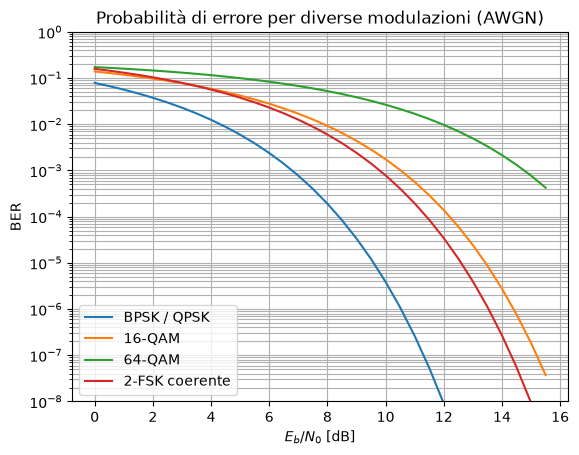

In [1]:
import numpy as np
from scipy.special import erfc
import matplotlib.pyplot as plt

def Q(x):
    return 0.5 * erfc(x / np.sqrt(2))

EbN0_dB = np.arange(0, 16, 0.5)
EbN0 = 10**(EbN0_dB / 10)

# BPSK / QPSK
ber_bpsk = Q(np.sqrt(2 * EbN0))

# 16-QAM (approssimazione)

ber_16qam = 3/4 * Q(np.sqrt(4 * EbN0 / 5))

# 64-QAM (approssimazione)
ber_64qam = 7/12 * Q(np.sqrt(2 * EbN0 / 7))

# 2-FSK coerente (3 dB peggiore di BPSK)
ber_2fsk = Q(np.sqrt(EbN0))

plt.semilogy(EbN0_dB, ber_bpsk, label="BPSK / QPSK")
plt.semilogy(EbN0_dB, ber_16qam, label="16-QAM")
plt.semilogy(EbN0_dB, ber_64qam, label="64-QAM")
plt.semilogy(EbN0_dB, ber_2fsk, label="2-FSK coerente")
plt.xlabel("$E_b/N_0$ [dB]")
plt.ylabel("BER")
plt.grid(True, which="both")
plt.legend()
plt.title("Probabilità di errore per diverse modulazioni (AWGN)")
plt.ylim(1e-8, 1)
plt.show()

Il grafico mostra il waterfall: per $E_b/N_0$ basse, tutte le modulazioni hanno BER alta; per $E_b/N_0$ alto, le curve scendono ripide. Lo spostamento orizzontale tra le curve è la **penalità di potenza** di ciascuna modulazione rispetto a BPSK/QPSK

## 7.7 Capacità di canale 

### Definizione 7.7.1 — Capacità secondo Shannon

Il teorema di Shannon-Hartley stabilisce che la capacità di un canale AWGN a banda limitata $B$ e rapporto segnale-rumore $S/N$ è:

$$
C = B \log_2\left(1 + \frac{S}{N}\right), \; [bit/s]
$$

La capacità è il **massimo bit rate** che può essere trasmesso con probabilità di errore arbitrariamente piccola, mediante codifica e modulazione opportune. È un limite asintotico: si raggiunge con codici di lunghezza infinita e complessità infinita. I sistemi reali si avvicinano alla capacità con codici moderni (LDPC, Turbo) e modulazioni adattive, ma non la raggiungono mai esattamente.

### Osservazione 7.7.2 — La capacità è un limite

La formula di Shannon dice quanto si può trasmettere, non come. Non dice quale modulazione usare, quale codice, quale forma d'impulso. È un limite superiore che vincola qualsiasi progetto: se un sistema tenta di trasmettere a un rate superiore alla capacità, la probabilità di errore non può essere resa arbitrariamente piccola, indipendentemente dalla codifica. Questo è il teorema converso di Shannon, ed è ciò che rende la capacità un vincolo invalicabile.

### Definizione 7.7.3 — La banda e la potenza come risorse scambiabili

La formula di Shannon mostra che la capacità dipende da due risorse: la banda $B$ e il raporto $S/N$. A parità di capacità si può:

- Aumentare $B$ e ridurre $S/N$ (più banda, meno potenza)

- Ridurre $B$ e aumentare $S/N$ (meno banda, più potenza)

Questo è il compromesso banda-potenza, ed è il cuore del progetto di un link. Per $B \to +\infty$, la capacità tende a: 

$$
C_{\infty} = \frac{S}{N_0} \log_2 e \approx 1.44\frac{S}{N_0}
$$

cioè la capacità cresce linearmente con $S/N_0$ (non con $B$), e c'è un limite finito alla capacità ottenibile aumentando la banda. Questo è il motivo per cui, nei link a potenza limitata (deep space), non ha senso aumentare la banda all'infinito: la capacità satura.

### Definizione 7.7.4 — Il limite di Shannon e l'efficienza energetica

Un modo utile di riscrivere la capacità è in termini $E_b/N_0$: 

$$
\frac{C}{B} = \log_2\left(1 + \frac{E_b}{N_0} \cdot \frac{C}{B}\right)
$$

Risolvendo per $E_b/N_0$ in funzione di $C/B$ (efficienza spettrale), si ottiene la **frontiera di Shannon:**

$$
\frac{E_b}{N_0} = \frac{2^{\frac{C}{B}} - 1}{\frac{C}{B}}
$$

Per $\frac{C}{B} \to 0$ (efficienza spettrale nulla, cioè banda infinita), il limite è 

$$
\lim_{\frac{C}{B} \to 0} \frac{E_b}{N_0} = \ln 2 \approx -1.59 dB
$$

Questo è il **limite di Shannon** (-1.59 dB): nessun sistema, per quanto sofisticato, può comunicare in modo affidabile con $E_b/N_0 < -1.59 dB$. I sistemi reali operano tipicamente a $E_b/N_0$ tra $0$ e $10$ dB, con un gap rispeto al limite che dipende dalla codifica e dalla modulazione 

### Osservazione 7.7.5 — Il limite di Shannon è il riferimento assoluto.

Il valore $−1.59$ dB è il "muro" oltre il quale nessuna tecnologia può andare. I sistemi reali (LTE, 5G, DVB-S2, CCSDS) si avvicinano a questo limite con un gap di $1–3$ dB, grazie a codici LDPC e Turbo e a modulazioni adattive. Il grafico BER vs $E_b/N_0$ con la curva di capacità sovrapposta è lo strumento standard per valutare l'efficienza di un sistema: più la curva è vicina al limite, più il sistema è efficiente.

## Link budget

### Definizione 7.8.1 — L'equazione del link

Il link budget è il bilancio tra la potenza trasmessa e la potenza ricevuta, tenendo conto di tutti i guadagni e le perdite lungo il percorso. L'equazione fondamentale è:

$$
P_r = P_t + G_t + G_r - L_{fs} - L_{atm} - L_{misc}
$$

dove: 
- $P_r$: potenza ricevuta (dBm o dBW);
- $P_t$: potenza trasmessa;
- $G_t$: guadagno dell'antenna trasmittente (dBi);
- $G_r$: guadagno dell'antenna ricevente (dBi);
- $L_{fs}$: perdita di spazio libero (free-space path loss);
- $L_{atm}$: perdita atmosferica (pioggia, nebbia, ossigeno);
- $L_{misc}$: altre perdite (cavi, connettori, puntamento).

La perdito di spazio libero e:

$$
L_{fs} = \left(\frac{4\pi d}{\lambda}\right)^2 = \left(\frac{4\pi d f_c}{c}\right)^2
$$

In dB: $L_{fs}[dB] = 20\log_{10}(d) + 20\log_{10}(f_c) + 20\log_{10}(4\pi/c)$, con $d$ in metri e $f_c$ in Hz. Per un satellite LEO a $500$ km e una portante a $437$ MHz, $L_{fs} \approx140$ dB.

### Definizione 7.8.2 — Il margine di link

Il margine di link è la differenza tra la potenza ricevuta e la potenza minima richiesta per il funzionamento (data la sensibilità del ricevitore e il $E_b/N_0$​ richiesto dalla modulazione e dalla codifica):

$$
M = P_r - P_{min} = P_r - \left( \frac{E_b}{N_0} \right)_{\text{req}} - N_0 - 10\log_{10}R_b
$$

Un margine positivo significa che il link funziona; un margine negativo significa che il link è sotto la soglia. In pratica, si progetta con un margine di $3-6$ dB per coprire fading, pioggia, puntamento, invecchiamento dei componenti.

### Osservazione 7.8.3 — Il link budget è il ponte tra la teoria e l'operazione.

Le formule dicono quale $E_b / N_0$ serve per una data BER. Il link budget dice quale $E_b/N_0$ si ottiene con una data antenna, potenza, distanza. Il progetto di un link consiste nel chiudere il bilancio: scegliere modulazione, codifica, antenna, potenza in modo che il margine sia positivo con un certo margine di sicurezza. È qui che la teoria statistica incontra l'ingegneria: la BER è una probabilità, il link budget è un'equazione, e il progetto è la sintesi delle due.

### Esempio 7.8.4 — Link budget semplificato in Python

In [2]:
import numpy as np

# Parametri del link (valori tipici per un CubeSat UHF)
P_t_dBW = 10 * np.log10(1.0)      # 1 W = 0 dBW
G_t_dBi = 2.0                     # antenna del satellite (dipolo)
G_r_dBi = 15.0                    # antenna della ground station (Yagi)
f_c = 437e6                       # 437 MHz
d = 500e3                         # 500 km
c = 3e8

# Perdita di spazio libero
L_fs_dB = 20*np.log10(4*np.pi*d*f_c/c)
print(f"L_fs = {L_fs_dB:.1f} dB")

# Potenza ricevuta
P_r_dBW = P_t_dBW + G_t_dBi + G_r_dBi - L_fs_dB
print(f"P_r = {P_r_dBW:.1f} dBW")

# Rumore: N0 = k*T, con T = 290 K (rumore termico) + figura di rumore
k_B = 1.38e-23
T_sys = 500.0                     # temperatura di sistema (K)
N0_dBW_Hz = 10*np.log10(k_B * T_sys)
print(f"N0 = {N0_dBW_Hz:.1f} dBW/Hz")

# E_b/N0 richiesto per BER 1e-5 con BPSK: circa 9.6 dB (senza codifica)
EbN0_req_dB = 9.6

# Bit rate massimo
# P_r = EbN0 + N0 + 10log10(Rb)  ->  Rb = 10^((P_r - EbN0 - N0)/10)
Rb_max = 10**((P_r_dBW - EbN0_req_dB - N0_dBW_Hz) / 10)
print(f"Rb massimo (senza codifica) = {Rb_max/1e3:.1f} kbit/s")

# Con margine di 3 dB
Rb_max_margin = 10**((P_r_dBW - EbN0_req_dB - N0_dBW_Hz - 3) / 10)
print(f"Rb con margine 3 dB = {Rb_max_margin/1e3:.1f} kbit/s")

L_fs = 139.2 dB
P_r = -122.2 dBW
N0 = -201.6 dBW/Hz
Rb massimo (senza codifica) = 9507.6 kbit/s
Rb con margine 3 dB = 4765.1 kbit/s


Interpretazione. Il codice calcola la perdita di spazio libero, la potenza ricevuta, il rumore, e il bit rate massimo compatibile con una BER target e un margine di sicurezza. È il tipo di calcolo che si fa in fase di progetto per dimensionare il link: se il bit rate richiesto è superiore a quello ottenibile, bisogna aumentare la potenza, il guadagno delle antenne, o migliorare la codifica.